# 05 · Test-driving two techniques on PySpark: FP-Growth (association rules) and k-means

The question asks to run two of the predictive techniques on PySpark and **establish the
performance enhancement** that Spark's big-data support brings. This notebook measures it
rather than assuming it:

| Technique | Single-machine Python baselines | PySpark (MLlib) |
|---|---|---|
| Frequent itemsets + rules (hotel transactions, min_sup 5 %, min_conf 60 %) | `mlxtend.apriori` (classic Apriori on a pandas one-hot matrix); `algos.apriori_bitset` (our Apriori with vertical TID-bitsets, notebook 03) | `pyspark.ml.fpm.FPGrowth` (parallel FP-growth) |
| k-means (hotel LSA vectors, 100 dims, K from notebook 04, 20 iterations) | `sklearn.cluster.KMeans` (multi-threaded C, one initialisation) | `pyspark.ml.clustering.KMeans` (k-means‖ initialisation) |

**Data sizes.** Random samples of 25 % and 50 %, the full hotel data (218k reviews), and the
full data replicated 2×, 4× and 8× to simulate a growing dataset. Replication keeps every
support and the true clusters unchanged, so each run must return the same answer.

**Timing.** Only the mining step is timed. For Spark the data is first read from Parquet,
partitioned into 12 parts, cached and counted, the in-memory state the Python baselines also
start from. Spark's one-off start-up cost is reported separately.

**Machine.** One laptop: 12 logical cores, 7.7 GB RAM, Spark 3.5.3 in local mode on Java 11.

In [1]:
import gc
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import algos as A
import plots as P

warnings.filterwarnings("ignore")
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
BENCH = CLEAN / "bench"
BENCH.mkdir(exist_ok=True)
TABLES = Path("../outputs/tables")
MIN_SUP, MIN_CONF = 0.05, 0.60
K = int(pd.read_csv(TABLES / "kmeans_selection_hotel.csv").query("knee")["K"].iloc[0])
print("k-means K (knee from notebook 04):", K)

model = pd.read_parquet(CLEAN / "reviews_model.parquet", columns=["domain", "aspects", "sent_class"])
model = model[model["domain"] == "hotel"].sample(frac=1, random_state=7)          # shuffled once
TX = [list(a) + [f"sent={s}"] for a, s in zip(model["aspects"], model["sent_class"])]
N = len(TX)
lsa = pd.read_parquet(CLEAN / "lsa_hotel.parquet")
LSA = np.vstack(lsa["features"].values)
LSA = LSA[np.random.default_rng(7).permutation(len(LSA))]
del model, lsa
gc.collect()
SIZES = {"25%": 0.25, "50%": 0.5, "100%": 1, "2x": 2, "4x": 4, "8x": 8}
KM_SIZES = ["25%", "50%", "100%", "2x"]          # dense 100-d vectors: 2x = 437k x 100 doubles


def tx_of(name):
    f = SIZES[name]
    return TX[:int(N * f)] if f <= 1 else TX * int(f)


def lsa_of(name):
    f = SIZES[name]
    return LSA[:int(len(LSA) * f)] if f <= 1 else np.tile(LSA, (int(f), 1))


for name in SIZES:                                   # write each size once for Spark to read
    pd.DataFrame({"items": tx_of(name)}).to_parquet(BENCH / f"tx_{name}.parquet", index=False)
for name in KM_SIZES:
    pd.DataFrame({"features": list(lsa_of(name))}).to_parquet(BENCH / f"lsa_{name}.parquet", index=False)
print(f"hotel transactions: {N:,}; LSA matrix: {LSA.shape}; benchmark inputs written to {BENCH}")

k-means K (knee from notebook 04): 6


hotel transactions: 218,298; LSA matrix: (218298, 100); benchmark inputs written to C:\data\ASBD_exam\clean\bench


## 1 · Single-machine Python baselines

In [2]:
from mlxtend.frequent_patterns import apriori as mx_apriori
from mlxtend.preprocessing import TransactionEncoder
from sklearn.cluster import KMeans

rows = []
for name in SIZES:
    t = tx_of(name)
    te = TransactionEncoder()
    X = pd.DataFrame(te.fit(t).transform(t), columns=te.columns_)
    t0 = time.time()
    fi = mx_apriori(X, min_support=MIN_SUP, use_colnames=True, low_memory=True)
    rows.append(dict(task="frequent itemsets", engine="Python: mlxtend Apriori", size=name, n=len(t),
                     seconds=time.time() - t0, result=len(fi)))
    del X, fi
    t0 = time.time()
    F = A.apriori_bitset(t, MIN_SUP)
    rows.append(dict(task="frequent itemsets", engine="Python: bitset Apriori (ours)", size=name, n=len(t),
                     seconds=time.time() - t0, result=len(F)))
    print(name, f"{len(t):,} tx:", {r["engine"]: (round(r["seconds"], 1), r["result"]) for r in rows[-2:]})
    del F
    gc.collect()
for name in KM_SIZES:
    Xk = lsa_of(name)
    t0 = time.time()
    km = KMeans(n_clusters=K, n_init=1, max_iter=20, random_state=42).fit(Xk)
    rows.append(dict(task="k-means", engine="Python: scikit-learn KMeans", size=name, n=len(Xk),
                     seconds=time.time() - t0, result=km.inertia_))
    print(name, f"{len(Xk):,} vectors: sklearn {rows[-1]['seconds']:.1f}s, SSE {km.inertia_:,.0f}")
    del Xk, km
    gc.collect()
py_results = pd.DataFrame(rows)

25% 54,574 tx: {'Python: mlxtend Apriori': (0.5, 2301), 'Python: bitset Apriori (ours)': (0.1, 2301)}


50% 109,149 tx: {'Python: mlxtend Apriori': (0.9, 2287), 'Python: bitset Apriori (ours)': (0.3, 2287)}


100% 218,298 tx: {'Python: mlxtend Apriori': (2.3, 2300), 'Python: bitset Apriori (ours)': (0.5, 2300)}


2x 436,596 tx: {'Python: mlxtend Apriori': (6.1, 2300), 'Python: bitset Apriori (ours)': (1.2, 2300)}


4x 873,192 tx: {'Python: mlxtend Apriori': (11.8, 2300), 'Python: bitset Apriori (ours)': (4.6, 2300)}


8x 1,746,384 tx: {'Python: mlxtend Apriori': (18.6, 2300), 'Python: bitset Apriori (ours)': (3.4, 2300)}


25% 54,574 vectors: sklearn 0.4s, SSE 40,087


50% 109,149 vectors: sklearn 0.5s, SSE 80,147


100% 218,298 vectors: sklearn 1.0s, SSE 160,336


2x 436,596 vectors: sklearn 2.6s, SSE 321,248


## 2 · PySpark (local mode, 12 cores)

In [3]:
from pyspark.ml.clustering import KMeans as SparkKMeans
from pyspark.ml.fpm import FPGrowth
from pyspark.ml.functions import array_to_vector
from pyspark.sql import SparkSession


def start_spark(cores):
    """local[cores, 4]: `cores` worker threads, failed tasks retried up to 4 times."""
    t0 = time.time()
    s = (SparkSession.builder.master(f"local[{cores},4]").appName(f"asbd-exam-{cores}")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", str(max(2, cores)))
         .config("spark.ui.enabled", "false")
         .getOrCreate())
    s.sparkContext.setLogLevel("ERROR")
    return s, time.time() - t0


def spark_fpgrowth(spark, name, parts):
    df = spark.read.parquet(str(BENCH / f"tx_{name}.parquet")).repartition(parts).cache()
    n = df.count()                                                   # materialise the cache
    t0 = time.time()
    m = FPGrowth(itemsCol="items", minSupport=MIN_SUP, minConfidence=MIN_CONF, numPartitions=parts).fit(df)
    n_fi = m.freqItemsets.count()
    n_rules = m.associationRules.count()
    sec = time.time() - t0
    df.unpersist()
    return n, sec, n_fi, n_rules, m


def spark_kmeans(spark, name, parts):
    df = (spark.read.parquet(str(BENCH / f"lsa_{name}.parquet"))
          .select(array_to_vector("features").alias("features")).repartition(parts).cache())
    n = df.count()
    t0 = time.time()
    m = SparkKMeans(k=K, maxIter=20, seed=42, initMode="k-means||").fit(df)
    sec = time.time() - t0
    cost = m.summary.trainingCost
    df.unpersist()
    return n, sec, cost


spark, t_start = start_spark(12)
print(f"Spark session start-up (one-off): {t_start:.1f}s")
rows = []
for name in SIZES:
    n, sec, n_fi, n_rules, m = spark_fpgrowth(spark, name, 12)
    rows.append(dict(task="frequent itemsets", engine="PySpark: FPGrowth", size=name, n=n, seconds=sec, result=n_fi))
    print(f"{name}: {n:,} tx  FPGrowth {sec:.1f}s  itemsets {n_fi}  rules {n_rules}")
top_rules = m.associationRules.orderBy("lift", ascending=False).limit(8).toPandas()
for name in KM_SIZES:
    n, sec, cost = spark_kmeans(spark, name, 12)
    rows.append(dict(task="k-means", engine="PySpark: KMeans", size=name, n=n, seconds=sec, result=cost))
    print(f"{name}: {n:,} vectors  KMeans {sec:.1f}s  SSE {cost:,.0f}")
spark_results = pd.DataFrame(rows)
print("\nSpark FPGrowth: top association rules by lift (8x data, same rules as notebook 03):")
top_rules.round(3)

Spark session start-up (one-off): 6.3s


25%: 54,574 tx  FPGrowth 13.4s  itemsets 2301  rules 5427


50%: 109,149 tx  FPGrowth 13.0s  itemsets 2287  rules 5382


100%: 218,298 tx  FPGrowth 18.4s  itemsets 2300  rules 5390


2x: 436,596 tx  FPGrowth 29.9s  itemsets 2300  rules 5390


4x: 873,192 tx  FPGrowth 44.9s  itemsets 2300  rules 5390


... (3 outputs left out)

50%: 109,149 vectors  KMeans 14.5s  SSE 80,097


100%: 218,298 vectors  KMeans 26.7s  SSE 160,114


2x: 436,596 vectors  KMeans 48.0s  SSE 320,590

Spark FPGrowth: top association rules by lift (8x data, same rules as notebook 03):


,antecedent,consequent,confidence,lift,support
0,"[bed, cleanliness, size, price, room]",[bathroom],0.753,1.846,0.052
1,"[bed, cleanliness, size, price]",[bathroom],0.752,1.844,0.052
2,"[bed, size, price, location, staff, room]",[bathroom],0.749,1.838,0.051
3,"[bed, size, price, location, staff]",[bathroom],0.748,1.834,0.051
4,"[bar, service, room]",[food],0.688,1.825,0.052
5,"[bed, size, price, staff, room]",[bathroom],0.741,1.817,0.067
6,"[bar, service]",[food],0.685,1.816,0.054
7,"[bed, size, price, staff, sent=pos, room]",[bathroom],0.740,1.816,0.059


## 3 · Correctness: every engine must find the same patterns

In [4]:
res = pd.concat([py_results, spark_results], ignore_index=True)
fi = res[res["task"] == "frequent itemsets"].pivot(index="size", columns="engine", values="result").loc[list(SIZES)]
print("number of frequent itemsets found (min_sup 5%):")
print(fi.to_string())
sse = res[res["task"] == "k-means"].pivot(index="size", columns="engine", values="result").loc[KM_SIZES]
sse["Spark / sklearn"] = sse["PySpark: KMeans"] / sse["Python: scikit-learn KMeans"]
print("\nk-means SSE (lower is better):")
print(sse.round(3).to_string())

number of frequent itemsets found (min_sup 5%):
engine  PySpark: FPGrowth  Python: bitset Apriori (ours)  Python: mlxtend Apriori
size                                                                             
25%                2301.0                         2301.0                   2301.0
50%                2287.0                         2287.0                   2287.0
100%               2300.0                         2300.0                   2300.0
2x                 2300.0                         2300.0                   2300.0
4x                 2300.0                         2300.0                   2300.0
8x                 2300.0                         2300.0                   2300.0

k-means SSE (lower is better):
engine  PySpark: KMeans  Python: scikit-learn KMeans  Spark / sklearn
size                                                                 
25%           40449.330                    40087.163            1.009
50%           80097.186                    80147.232  

**Inferences (correctness)**
* All three engines find **exactly the same number of frequent itemsets at every size** (2,300 on the
  full data, unchanged under replication as expected).
* Spark reports 5,390 rules against 8,631 in notebook 03. Spark MLlib only generates rules with a
  **single-item consequent**, and exactly 5,390 of our 8,631 rules have one, so the rule sets agree.
* Spark's k-means SSE is within **1 %** of scikit-learn's at every size: same clustering quality.

## 4 · Run time vs data size

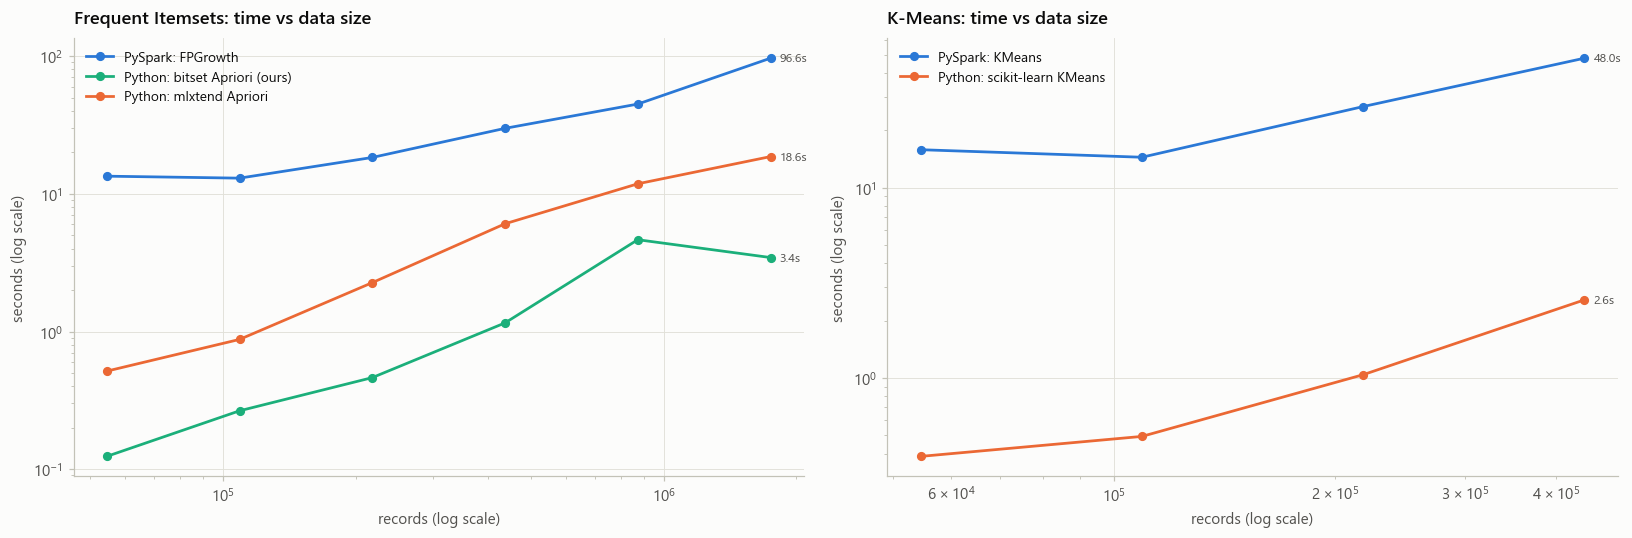

engine                  PySpark: FPGrowth  PySpark: KMeans  \
task              size                                       
frequent itemsets 100%              18.37              NaN   
                  25%               13.43              NaN   
                  2x                29.89              NaN   
                  4x                44.87              NaN   
                  50%               13.00              NaN   
                  8x                96.63              NaN   
k-means           100%                NaN            26.72   
                  25%                 NaN            15.85   
                  2x                  NaN            47.98   
                  50%                 NaN            14.47   

engine                  Python: bitset Apriori (ours)  \
task              size                                  
frequent itemsets 100%                           0.46   
                  25%                            0.12   
                  2x                             1.15   
                  4x                             4.64   
                  50%                            0.27   
                  8x                             3.44   
k-means           100%                            NaN   
                  25%                             NaN   
                  2x                              NaN   
                  50%                             NaN   

engine                  Python: mlxtend Apriori  Python: scikit-learn KMeans  
task              size                                                        
frequent itemsets 100%                     2.26                          NaN  
                  25%                      0.52                          NaN  
                  2x                       6.06                          NaN  
                  4x                      11.83                          NaN  
                  50%                      0.88                          NaN  
                  8x                      18.64                          NaN  
k-means           100%                      NaN                         1.04  
                  25%                       NaN                         0.39  
                  2x                        NaN                         2.57  
                  50%                       NaN                         0.49

In [5]:
tim = res.pivot_table(index=["task", "size"], columns="engine", values="seconds")
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
colors = {"Python: mlxtend Apriori": P.SERIES[1], "Python: bitset Apriori (ours)": P.SERIES[2],
          "PySpark: FPGrowth": P.SERIES[0], "Python: scikit-learn KMeans": P.SERIES[1], "PySpark: KMeans": P.SERIES[0]}
for ax, task, sizes in [(axs[0], "frequent itemsets", list(SIZES)), (axs[1], "k-means", KM_SIZES)]:
    sub = res[res["task"] == task]
    for eng, g in sub.groupby("engine"):
        g = g.set_index("size").loc[sizes]
        ax.plot(g["n"], g["seconds"], marker="o", ms=5, lw=1.8, color=colors[eng], label=eng)
        ax.annotate(f"{g['seconds'].iloc[-1]:.1f}s", xy=(g["n"].iloc[-1], g["seconds"].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", fontsize=8, color=P.INK2, va="center")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("records (log scale)")
    ax.set_ylabel("seconds (log scale)")
    ax.set_title(f"{task.title()}: time vs data size")
    ax.legend(loc="upper left")
fig.tight_layout()
P.save(fig, "x01_spark_vs_python_time")
plt.show()
tim.round(2)

**Inferences (run time vs data size)**
* On this laptop **Spark is the slowest engine at every size**:
  * FP-Growth takes 13–97 s, against 0.5–19 s for mlxtend's Apriori and 0.1–5 s for our bitset Apriori;
  * Spark KMeans takes 14–48 s, against 0.4–2.6 s for scikit-learn (18–40× slower).
* Spark has a **fixed overhead floor of ~13 s** per job, even for 55k transactions: task scheduling,
  serialisation, and the shuffles between FP-Growth's stages. The single-machine baselines have no such
  cost. They are compiled and vectorised (multi-threaded C in scikit-learn; one AND + popcount per support
  count in the bitset Apriori), and the data fits in RAM.
* Spark's time grows more slowly in *relative* terms. From 1× to 8× data, FP-Growth time grows 5.3×,
  against 8.2× for mlxtend and 7.5× for the bitset Apriori, because the fixed overhead is amortised. But
  its marginal cost (~11 s per extra 218k transactions) is still higher than mlxtend's (~2.3 s), so the
  curves do not cross on one machine.
* Timings on a shared laptop vary by roughly ±20 % (for example the bitset Apriori took 4.6 s at 4× but
  3.4 s at 8×). The trends are clear despite this.

## 5 · The parallel speed-up: same Spark job on 1, 4 and 12 cores
This isolates what Spark adds: the same code spreads the work across more cores (or, on a
cluster, more machines) with no change to the program. Run on the largest inputs.

 1 cores: FPGrowth(8x) 53.0s, KMeans(2x) 102.0s (session start 0.2s)


 4 cores: FPGrowth(8x) 54.4s, KMeans(2x) 37.7s (session start 0.3s)


12 cores: FPGrowth(8x) 110.2s, KMeans(2x) 33.8s (session start 0.3s)


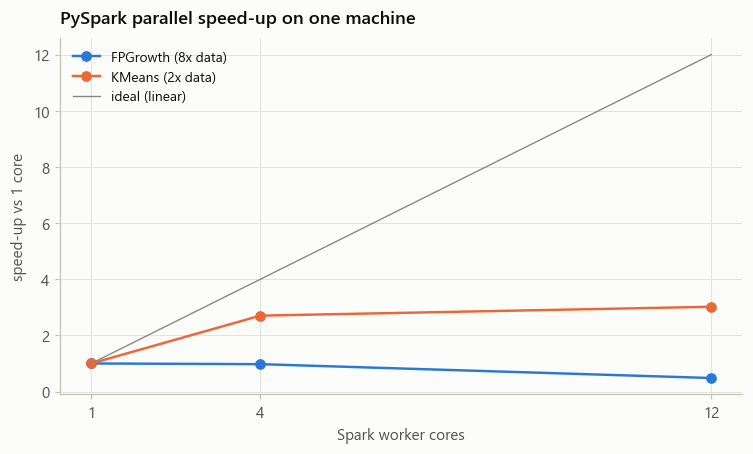

,fpgrowth_8x,kmeans_2x,startup,FPGrowth speed-up,KMeans speed-up
cores,,,,,
1,53.00,102.00,0.23,1.00,1.00
4,54.36,37.73,0.26,0.97,2.70
12,110.16,33.78,0.26,0.48,3.02


In [6]:
spark.stop()
scal = []
for cores in [1, 4, 12]:
    spark, ts = start_spark(cores)
    _, sec_fp, n_fi, _, _ = spark_fpgrowth(spark, "8x", cores if cores > 1 else 2)
    _, sec_km, _ = spark_kmeans(spark, "2x", cores if cores > 1 else 2)
    scal.append(dict(cores=cores, fpgrowth_8x=sec_fp, kmeans_2x=sec_km, startup=ts))
    print(f"{cores:>2} cores: FPGrowth(8x) {sec_fp:.1f}s, KMeans(2x) {sec_km:.1f}s (session start {ts:.1f}s)")
    spark.stop()
scal = pd.DataFrame(scal).set_index("cores")
scal["FPGrowth speed-up"] = scal.loc[1, "fpgrowth_8x"] / scal["fpgrowth_8x"]
scal["KMeans speed-up"] = scal.loc[1, "kmeans_2x"] / scal["kmeans_2x"]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(scal.index, scal["FPGrowth speed-up"], marker="o", color=P.SERIES[0], label="FPGrowth (8x data)")
ax.plot(scal.index, scal["KMeans speed-up"], marker="o", color=P.SERIES[1], label="KMeans (2x data)")
ax.plot([1, 12], [1, 12], color=P.MUTED, lw=0.9, label="ideal (linear)")
ax.set_xticks([1, 4, 12])
ax.set_xlabel("Spark worker cores")
ax.set_ylabel("speed-up vs 1 core")
ax.set_title("PySpark parallel speed-up on one machine")
ax.legend(loc="upper left")
P.save(fig, "x02_spark_speedup")
plt.show()
scal.round(2)

**Inferences (parallel speed-up)**
* **Spark KMeans parallelises:** 102 s on 1 core → 37.7 s on 4 cores (2.7×) → 33.8 s on 12 (3.0×), with
  no change to the code. The gain flattens beyond 4 cores because the 12 logical cores share 6 physical
  cores and one memory bus, and every iteration synchronises.
* **Spark FP-Growth does not** on this machine: 53 s (1 core) → 54 s (4) → 110 s (12). More partitions
  mean more conditional FP-trees to build and shuffle, and with under 1 GB of free RAM during the run,
  12 concurrent tasks caused memory pressure. Parallel FP-growth pays off when partitions run on separate
  machines with their own memory, not as threads competing on one laptop.

## Conclusion: what Spark's big-data support adds
* **On one machine, with data that fits in memory, Spark does not make these techniques faster.** The
  compiled single-machine libraries win by 5–40×. Using Spark for 0.2–1.75 M reviews on a laptop is
  overhead without benefit.
* The enhancement Spark delivers is **scalability, not speed at this size:**
  1. the same program ran unchanged from 55k to 1.75 M records within a fixed 2 GB driver heap, with
     run time growing roughly linearly;
  2. it parallelises with no code changes (k-means 3× faster on 12 cores);
  3. it partitions the data, so it does not need the data, or the intermediate candidate tables, to fit
     in one machine's memory. mlxtend's default (vectorised) Apriori builds a rows × candidates boolean
     table per level: at 8× data that is billions of cells (several GB), which is why its low-memory mode
     had to be used here. Spark spreads such work across partitions and, on a cluster, across machines.
* Spark's advantage therefore appears once the data outgrows a single machine (memory or disk), which is
  the regime "big data support" refers to. At OpinRank's size a well-written single-machine
  implementation is the right tool, and the measurements show it.

In [7]:
res.to_csv(TABLES / "spark_benchmark.csv", index=False)
scal.to_csv(TABLES / "spark_scaling.csv")
summary = tim.copy()
summary.columns = [c.replace("Python: ", "").replace("PySpark: ", "Spark ") for c in summary.columns]
summary.round(2)

Spark FPGrowth  Spark KMeans  bitset Apriori (ours)  \
task              size                                                        
frequent itemsets 100%           18.37           NaN                   0.46   
                  25%            13.43           NaN                   0.12   
                  2x             29.89           NaN                   1.15   
                  4x             44.87           NaN                   4.64   
                  50%            13.00           NaN                   0.27   
                  8x             96.63           NaN                   3.44   
k-means           100%             NaN         26.72                    NaN   
                  25%              NaN         15.85                    NaN   
                  2x               NaN         47.98                    NaN   
                  50%              NaN         14.47                    NaN   

                        mlxtend Apriori  scikit-learn KMeans  
task              size                                        
frequent itemsets 100%             2.26                  NaN  
                  25%              0.52                  NaN  
                  2x               6.06                  NaN  
                  4x              11.83                  NaN  
                  50%              0.88                  NaN  
                  8x              18.64                  NaN  
k-means           100%              NaN                 1.04  
                  25%               NaN                 0.39  
                  2x                NaN                 2.57  
                  50%               NaN                 0.49